# ECG Signal Classification Using Logistic Regression


In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report, ConfusionMatrixDisplay

np.random.seed(42)
np.set_printoptions(suppress=True)
warnings.simplefilter("error", ConvergenceWarning)

## 1. Explore and preprocess the data

In [2]:
a = np.loadtxt("ECG200/ECG200_TRAIN.txt")
b = np.loadtxt("ECG200/ECG200_TEST.txt")
X, y = a[:, 1:], a[:, 0]
Xt, yt = b[:, 1:], b[:, 0]

print("train:", X.shape)
print("test:", Xt.shape)
print("sequence length:", X.shape[1])
print("labels:", np.unique(y, return_counts=True))
print("test labels:", np.unique(yt, return_counts=True))

train: (100, 96)
test: (100, 96)
sequence length: 96
labels: (array([-1.,  1.]), array([31, 69]))
test labels: (array([-1.,  1.]), array([36, 64]))


Label -1 is Myocardial Infarction (MI) and 1 is Normal. MI is converted to 1 and Normal to 0.

In [3]:
print("missing train:", np.isnan(X).sum(), "missing test:", np.isnan(Xt).sum())

y = (y == -1).astype(int)
yt = (yt == -1).astype(int)
k = ["Normal", "MI"]

print("train class distribution:", np.bincount(y))
print("test class distribution:", np.bincount(yt))

missing train: 0 missing test: 0
train class distribution: [69 31]
test class distribution: [64 36]


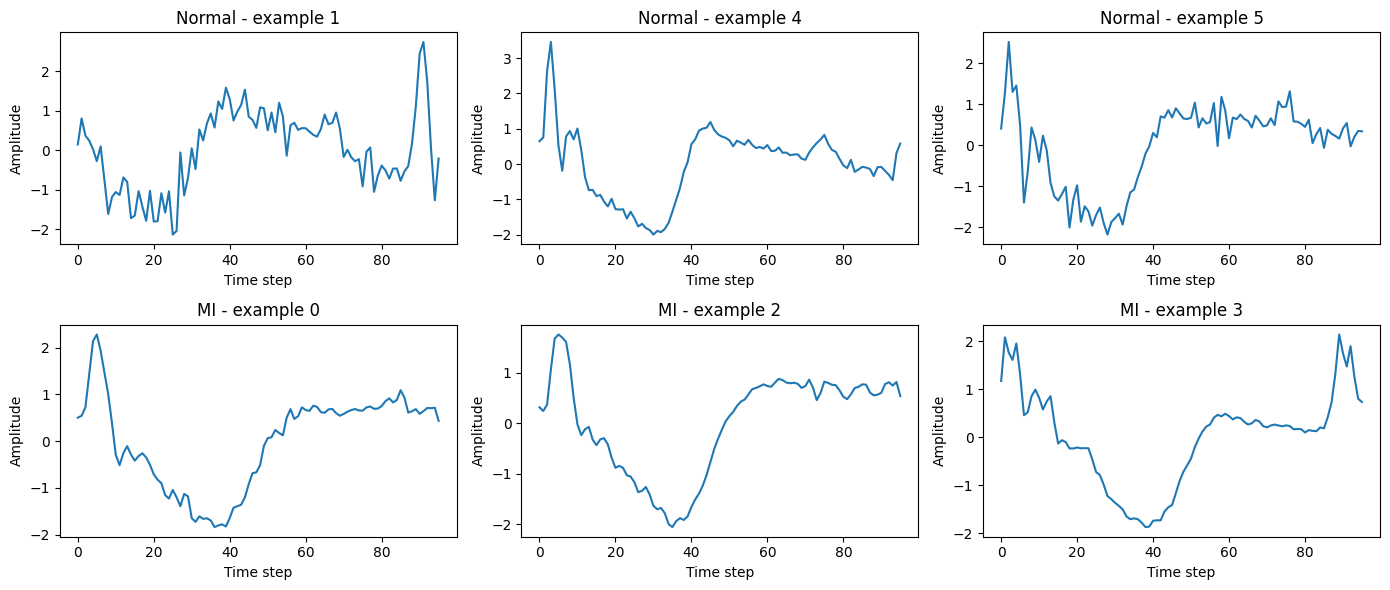

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for i in [0, 1]:
    for j, n in enumerate(np.where(y == i)[0][:3]):
        ax[i, j].plot(X[n])
        ax[i, j].set_title(f"{k[i]} - example {n}")
        ax[i, j].set_xlabel("Time step")
        ax[i, j].set_ylabel("Amplitude")
plt.tight_layout()
plt.show()

In [5]:
X1, X2, y1, y2 = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train subset:", X1.shape, np.bincount(y1))
print("validation:", X2.shape, np.bincount(y2))

train subset: (80, 96) [55 25]
validation: (20, 96) [14  6]


Standardization is done with a `StandardScaler` fit on the training subset only and then applied to the validation and test sets (inside `run` below).

## 2. Input representations

**Experiment A:** the 96 raw values in their original order.

**Experiment B:** 10 extracted features. For a sequence x_1 ... x_N with N = 96, m = mean and s = standard deviation:

| Feature | Formula | Relevance |
|---|---|---|
| Minimum | min(x) | depth of the lowest wave (ST depression in MI) |
| Maximum | max(x) | height of the R peak |
| Median | middle value of sorted x | baseline level / ST shift |
| Skewness | mean((x - m)^3) / s^3 | asymmetry between peaks and dips |
| Kurtosis | mean((x - m)^4) / s^4 - 3 | how sharp the peaks are |
| Mean absolute difference | mean(abs(x_(t+1) - x_t)) | how fast the signal changes |
| Maximum absolute slope | max(abs(x_(t+1) - x_t)) | steepness of the QRS complex |
| Zero crossings | number of t where x_t * x_(t+1) < 0 | number of oscillations |
| Time of maximum | index of max(x) | position of the R peak |
| Time of minimum | index of min(x) | position of the lowest point |

Every ECG200 series is already z-normalised, so mean, standard deviation, RMS and energy are the same for all signals (checked below) and are left out. Peak-to-peak is left out because it equals maximum minus minimum.

In [6]:
print("std of per-series mean:", X.mean(1).std())
print("std of per-series std:", X.std(1).std())

def feats(z):
    d = np.diff(z, axis=1)
    return np.column_stack([z.min(1), z.max(1), np.median(z, 1), skew(z, axis=1), kurtosis(z, axis=1),
                            np.abs(d).mean(1), np.abs(d).max(1), (z[:, :-1] * z[:, 1:] < 0).sum(1),
                            z.argmax(1), z.argmin(1)])

F1, F2, Ft = feats(X1), feats(X2), feats(Xt)
print(F1.shape, F2.shape, Ft.shape)

std of per-series mean: 1.5833837229600733e-09
std of per-series std: 2.4783798834427325e-09
(80, 10) (20, 10) (100, 10)


## 3. Logistic regression

**Weighted sum and bias:** z = w1*x1 + w2*x2 + ... + wd*xd + b. Each weight shows how much an input pushes the prediction towards class 1, the bias shifts the score.

**Sigmoid:** p = 1 / (1 + e^(-z)), the probability that y = 1.

**Binary cross-entropy loss:** L = -(1/n) * sum[y*log(p) + (1-y)*log(1-p)]. It is small when the correct class gets a high probability.

**Regularization:** L2 adds 0.5 * ||w||^2 to the loss so the weights stay small and the model overfits less. In scikit-learn `C` is the inverse of the regularization strength, so a smaller `C` means stronger regularization. L2 is the default penalty of `LogisticRegression`.

**Decision threshold:** predict 1 if p >= 0.5, otherwise 0.

**Settings:** `LogisticRegression` with the lbfgs solver, L2 penalty, `max_iter=10000`, `random_state=42`. `C` values tried: 0.001, 0.01, 0.1, 1, 10, 100. The best `C` is the one with the highest validation macro-F1. Convergence warnings are turned into errors, so the notebook running to the end means every model converged.

In [7]:
cs = [0.001, 0.01, 0.1, 1, 10, 100]

def run(A, V, T):
    s = StandardScaler().fit(A)
    A, V, T = s.transform(A), s.transform(V), s.transform(T)
    r = []
    for c in cs:
        m = LogisticRegression(C=c, max_iter=10000, random_state=42).fit(A, y1)
        p = m.predict_proba(V)[:, 1]
        q = (p >= 0.5).astype(int)
        r.append([c, accuracy_score(y1, m.predict(A)), accuracy_score(y2, q), f1_score(y2, q, average="macro"), roc_auc_score(y2, p)])
    r = np.array(r)
    c = r[r[:, 3].argmax(), 0]
    m = LogisticRegression(C=c, max_iter=10000, random_state=42).fit(A, y1)
    print("C | train acc | val acc | val macro-F1 | val AUC")
    print(np.round(r, 3))
    print("selected C:", c)
    return m, T, r, c

### Experiment A

In [8]:
mA, TA, rA, cA = run(X1, X2, Xt)

C | train acc | val acc | val macro-F1 | val AUC
[[  0.001   0.725   0.7     0.412   0.917]
 [  0.01    0.85    0.85    0.812   0.94 ]
 [  0.1     0.925   0.85    0.812   0.952]
 [  1.      0.988   0.85    0.829   0.976]
 [ 10.      1.      0.9     0.89    1.   ]
 [100.      1.      0.85    0.84    1.   ]]
selected C: 10.0


### Experiment B

In [9]:
mB, TB, rB, cB = run(F1, F2, Ft)

C | train acc | val acc | val macro-F1 | val AUC
[[  0.001   0.688   0.7     0.412   0.679]
 [  0.01    0.7     0.7     0.412   0.69 ]
 [  0.1     0.8     0.8     0.733   0.75 ]
 [  1.      0.788   0.75    0.687   0.786]
 [ 10.      0.788   0.8     0.762   0.786]
 [100.      0.8     0.85    0.812   0.821]]
selected C: 100.0


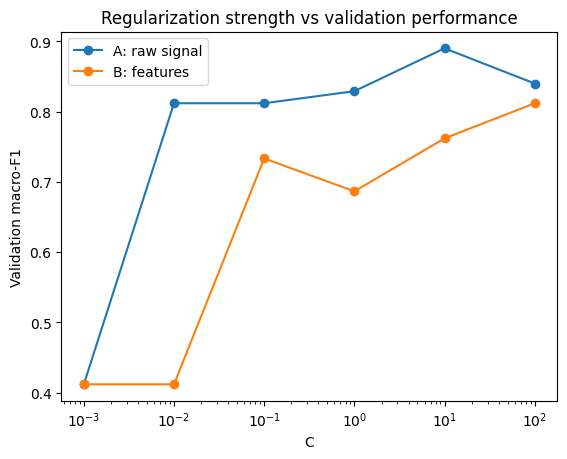

In [10]:
plt.plot(cs, rA[:, 3], "o-", label="A: raw signal")
plt.plot(cs, rB[:, 3], "o-", label="B: features")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Validation macro-F1")
plt.title("Regularization strength vs validation performance")
plt.legend()
plt.show()

## 4. Evaluate and compare on the test set

In [11]:
res = {}
for n, m, T in [("A: raw signal", mA, TA), ("B: features", mB, TB)]:
    p = m.predict_proba(T)[:, 1]
    q = (p >= 0.5).astype(int)
    print(n)
    print(classification_report(yt, q, target_names=k, digits=3))
    res[n] = [accuracy_score(yt, q), f1_score(yt, q, average="macro"), roc_auc_score(yt, p), p, q]

A: raw signal
              precision    recall  f1-score   support

      Normal      0.883     0.828     0.855        64
          MI      0.725     0.806     0.763        36

    accuracy                          0.820       100
   macro avg      0.804     0.817     0.809       100
weighted avg      0.826     0.820     0.822       100

B: features
              precision    recall  f1-score   support

      Normal      0.764     0.859     0.809        64
          MI      0.679     0.528     0.594        36

    accuracy                          0.740       100
   macro avg      0.721     0.694     0.701       100
weighted avg      0.733     0.740     0.731       100



In [12]:
print(f"{'':16}{'Accuracy':>10}{'Macro-F1':>10}{'ROC-AUC':>10}")
for n in res:
    print(f"{n:16}{res[n][0]:10.3f}{res[n][1]:10.3f}{res[n][2]:10.3f}")

                  Accuracy  Macro-F1   ROC-AUC
A: raw signal        0.820     0.809     0.899
B: features          0.740     0.701     0.832


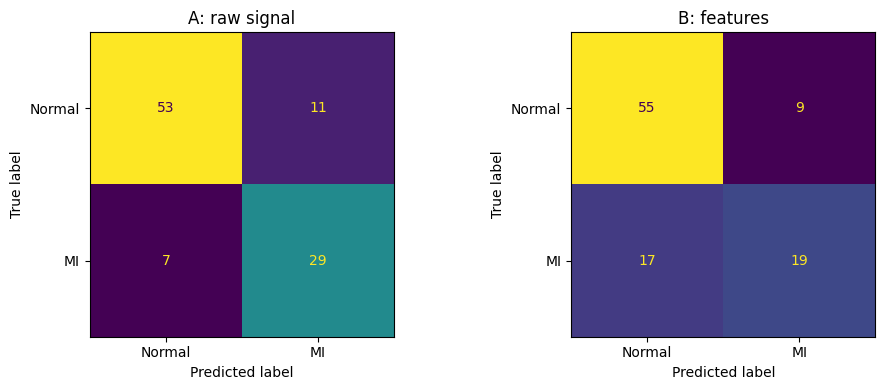

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, n in enumerate(res):
    ConfusionMatrixDisplay(confusion_matrix(yt, res[n][4]), display_labels=k).plot(ax=ax[i], colorbar=False)
    ax[i].set_title(n)
plt.tight_layout()
plt.show()

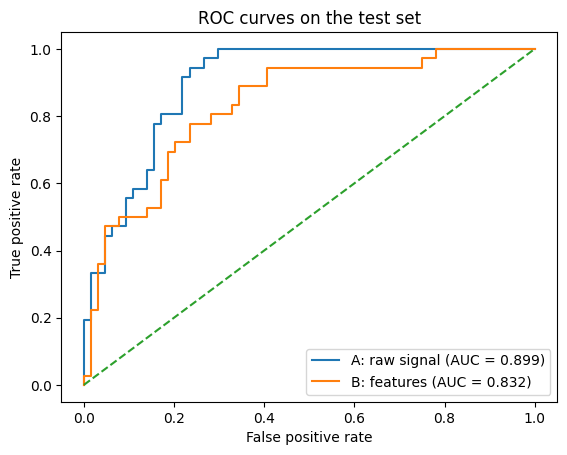

In [14]:
for n in res:
    f, t, _ = roc_curve(yt, res[n][3])
    plt.plot(f, t, label=f"{n} (AUC = {res[n][2]:.3f})")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the test set")
plt.legend()
plt.show()

## 5. Discussion of findings

**1. Which input representation performed better, and what evidence supports your conclusion?**

The raw signal one (Experiment A) did better on pretty much everything. On the test set it got 82% accuracy and the features one (Experiment B) got 74%. Macro F1 was 0.81 for raw and 0.70 for features and ROC-AUC was 0.90 vs 0.83 so in the ROC plot the blue line is above the orange one most of the way. The biggest difference is finding the heart attack (MI) signals, raw found 29 out of 36 (recall 0.81) but features only found 19 out of 36 (recall 0.53) so it missed almost half of them which is really bad for a sick person. Features was only a little better at Normal recall (0.86 vs 0.83).

**2. What information may be lost when replacing raw signals with summary features?**

When we turn 96 numbers into just 10 numbers we lose most of the details about the shape and the timing of the heartbeat. Stuff like min, max, median, skewness and kurtosis dont care about the order of the values at all so if you mix up all the points the numbers stay the same but the heartbeat would look totally different. So we lose things like where the signal goes down and for how long, how wide the big spike is, what the wave after it looks like and how far apart the waves are. I kept argmax and argmin to keep a little bit of timing but thats only 2 points out of 96. Also the dataset was already z normalised so mean, std, RMS and energy were the same for every signal and we had to throw them out because they tell the model nothing.

**3. Does logistic regression explicitly model temporal dependencies? Explain how it uses the 96 raw input values.**

No it doesnt. Logistic regression just gives every one of the 96 values its own weight, multiplies them, adds them all up with the bias (z = w1x1 + w2x2 + ... + w96x96 + b) and then puts z into the sigmoid to get a probability. It treats every time step like a separate column in a table and it has no idea that step 10 is right next to step 11. If you shuffled the columns the same way for every signal and trained again you would get the same results just with shuffled weights. The only "time" thing it has is that each position has its own weight, so it can learn like "high values here means MI". But if the heartbeat is moved a little bit left or right the values land on different weights and the model can get it wrong.

**4. How did regularization affect performance?**

Regularization made a big difference. When C was really small (0.001) the regularization was way too strong and the weights got squished almost to zero so both models just said Normal for everything and validation macro F1 was only 0.41 (thats useless). The features model was still stuck at 0.41 at C = 0.01 too. As C got bigger both got better. For raw the best was C = 10 (validation macro F1 0.89) and at C = 100 it went down to 0.84 even though training accuracy was already 100%, so it was starting to overfit and memorize the 80 training signals. The raw model needs regularization more because it has 96 inputs and only 80 training signals. The features model liked the weakest one we tried (C = 100) and its training accuracy only got to about 80% so it was not overfitting, it was more like underfitting because 10 features is not enough info. Since its best C was at the end of the list, bigger C values could maybe be a tiny bit better but probably not much.

**5. What are the limitations of logistic regression for ECG classification?**

- It can only draw a straight line (linear boundary) between the two classes so if the difference between normal and MI is complicated it cant learn it unless a person makes better features by hand.
- It doesnt understand time or shapes like a CNN or RNN would, and if the beat is shifted a bit in time it gets confused.
- Neighbor time steps are very similar to each other (correlated) so the weights can come out weird and hard to explain and you need regularization to keep them under control.
- With features its only as good as the features a person picks, and our features missed almost half of the MI cases.
- It uses a threshold of 0.5 and with uneven classes that might not be the best one, in a hospital missing a heart attack is way worse than a false alarm so you would probably want a lower threshold.
- It only looks at one heartbeat from one lead but real doctors look at 12 leads and lots of beats.

**6. Why should conclusions from this small dataset be interpreted cautiously?**

The dataset is really small, only 100 signals for training and 100 for testing, and our validation set was only 20 signals (14 normal and 6 MI). So getting just 1 signal right or wrong changes validation accuracy by 5% which can change which C gets picked. The test set only has 36 MI signals so MI recall changes by almost 3% for every single signal. If we used a different random split for validation we might pick a different C and get different test numbers. The classes are also uneven (about 2 normal for every 1 MI). And all of the signals come from one old dataset that was already cleaned and cut into single beats, so the model might not work on real ECGs from other machines or other people. So we can say raw did better here but we cant say for sure it will always be better.